# Clasificación de dígitos MNIST con perceptrones multicapa (MLP)

Se utiliza el conjunto de datos MNIST, formado por imágenes en escala de grises de dígitos escritos a mano.

El objetivo principal consiste en emplear estos datos para entrenar distintas Redes Neuronales Artificiales (RNA) basadas en Perceptrones Multicapa (MLP), que tengan la capacidad de reconocer patrones en las imágenes y clasificarlas según el dígito que representan.

Dado que cada imagen está etiquetada, el modelo aprenderá a partir de ejemplos conocidos y comparará sus predicciones con las etiquetas correctas para calcular el error de predicción. Por ello, se trata de aprendizaje supervisado.

Se entrenan varias arquitecturas MLP con tres y cuatro capas ocultas, variando el número de neuronas en cada una para analizar cómo influye en el rendimiento.

Un MLP es un tipo de red neuronal que tiene varias capas de neuronas conectadas unas con otras. La información entra por la capa de entrada, pasa a través de las capas ocultas y cuando llega a la capa de salida se obtiene la predicción. Cada neurona recibe información de las capas anteriores, la combina con sus pesos y sesgo y aprende patrones a través de una función de activación.

Durante el entrenamiento, la red ajusta sus pesos y sesgos mediante retropropagación. En este proceso, la función de pérdida mide cuánto se equivoca el modelo y calcula los gradientes necesarios para corregir esos errores. El optimizador utiliza estos gradientes para ajustar los parámetros y reducir la pérdida.

Finalmente, se comparará el desempeño de los diferentes modelos evaluando su capacidad para predecir correctamente los dígitos en datos que no han sido vistos durante el entrenamiento.

**LIBRERÍAS**

In [28]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tabulate import tabulate

**1. CARGA Y PREPARACIÓN DE LOS DATOS**

En primer lugar, realizamos una preparación y exploración inicial del conjunto de datos MNIST.

In [29]:
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

In [30]:
print("Número de imágenes en train:", X_train_full.shape)
print("Número de imágenes en test:", X_test.shape)
print("Valor mínimo píxel:", X_train_full.min())
print("Valor máximo píxel:", X_train_full.max())
print("Mínimo etiquetas:", y_train_full.min())
print("Máximo etiquetas:", y_train_full.max())

Número de imágenes en train: (60000, 28, 28)
Número de imágenes en test: (10000, 28, 28)
Valor mínimo píxel: 0
Valor máximo píxel: 255
Mínimo etiquetas: 0
Máximo etiquetas: 9


El conjunto de datos está formado por 70.000 imágenes, de las cuales 60.000 se corresponden con el conjunto de entrenamiento y 10.000 con el conjunto de prueba. Cada imagen tiene un tamaño de 28x28 píxeles y está representada en escala de grises, con una intensidad entre 0 (negro) y 255 (blanco).

 Por otro lado, la variable objetivo contiene etiquetas numéricas del 0 al 9, correspondientes al dígito que representan en la imagen.

 Esta variable se distribuye de la siguiente forma:

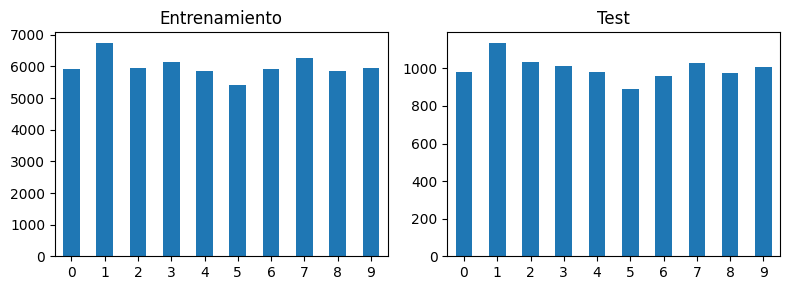

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
pd.Series(y_train_full).value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Entrenamiento")
axes[0].tick_params(axis='x', rotation=0)
pd.Series(y_test).value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set_title("Test")
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

En los gráficos de barras observamos que los dígitos que más aparecen son el 1 y el 7 tanto en el conjunto de entrenamiento como en test. Por otro lado, el que menos frecuencia presenta es el 5.

Sin embargo, los datos no muestran un desbalance muy marcado, ya que las diferencias entre las categorías son pequeñas. Por ello, podemos considerar que la distribución de la variable respuesta es bastante equilibrada.

A partir del conjunto de entrenamiento realizamos una partición adicional para obtener un subconjunto de validación, asignando 55.000 imágenes al entrenamiento y 5.000 a la validación. Además, normalizamos los valores de los píxeles dividiéndolos entre 255, para que sus intensidades queden entre 0 y 1:

In [32]:
X_valid, X_train = X_train_full[:5000] / 255., X_train_full[5000:] / 255.
y_valid, y_train = y_train_full[:5000], y_train_full[5000:]
X_test = X_test / 255.

Mostramos una pequeña muestra de algunas imágenes junto con sus etiquetas:

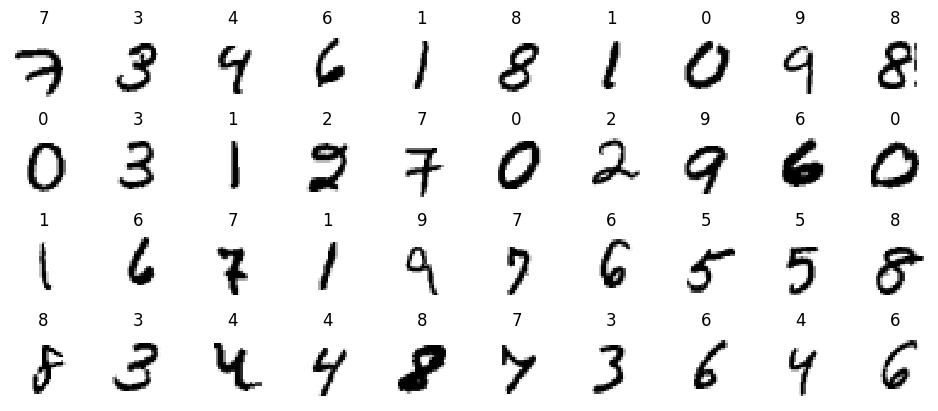

In [33]:
n_rows = 4
n_cols = 10
plt.figure(figsize=(n_cols * 1.2, n_rows * 1.2))
for row in range(n_rows):
    for col in range(n_cols):
        index = n_cols * row + col
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(X_train[index], cmap="binary", interpolation="nearest")
        plt.axis('off')
        plt.title(y_train[index])
plt.subplots_adjust(wspace=0.2, hspace=0.5)
plt.show()

**2. BÚSQUEDA DE LA TASA DE APRENDIZAJE ÓPTIMA**

Antes de entrenar los modelos, es importante determinar una tasa de aprendizaje (Learning Rate) adecuada. El learning rate es un hiperparámetro que controla cuánto cambian los pesos de la red en cada iteración de la retropropagación.

Para identificar un valor apropiado, entrenamos un modelo sencillo durante una sola época empezando por un LR muy bajo (0.001), que se incrementa de forma exponencial en cada batch mediante el callback *ExponentialLearningRate*, usando un factor de 1.005 (un aumento del 0.5% por lote).

Al observar cómo evoluciona la pérdida a medida que aumenta el LR, podemos detectar cuándo el modelo empieza a aprender y cuándo la pérdida se empieza a disparar. Este valor del LR nos servirá como referencia para el entrenamiento de los modelos más complejos.

Creación del callback *ExponentialLearningRate*:

In [34]:
class ExponentialLearningRate(tf.keras.callbacks.Callback):
    def __init__(self, factor):
        self.factor = factor
        self.rates = []
        self.losses = []

    def on_batch_end(self, batch, logs=None):
        lr = self.model.optimizer.learning_rate.numpy() * self.factor
        self.model.optimizer.learning_rate = lr
        self.rates.append(lr)
        self.losses.append(logs["loss"])

In [37]:
tf.keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

In [38]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(300, activation="relu"),
    tf.keras.layers.Dense(100, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

In [39]:
optimizer = tf.keras.optimizers.SGD(learning_rate=1e-3)
model.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
              metrics=["accuracy"])
expon_lr = ExponentialLearningRate(factor=1.005)

In [40]:
history = model.fit(X_train, y_train, epochs=1,
                    validation_data=(X_valid, y_valid),
                    callbacks=[expon_lr])

1719/1719 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.5202 - loss: nan - val_accuracy: 0.0958 - val_loss: nan


Graficamos la pérdida en función de la tasa de aprendizaje:

Text(0, 0.5, 'Loss')

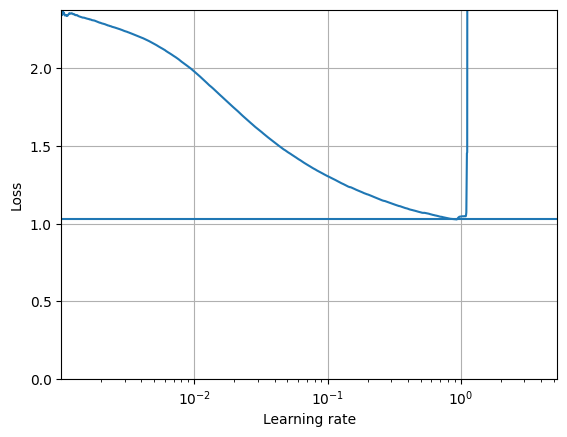

In [41]:
plt.plot(expon_lr.rates, expon_lr.losses)
plt.gca().set_xscale('log')
plt.hlines(min(expon_lr.losses), min(expon_lr.rates), max(expon_lr.rates))
plt.axis([min(expon_lr.rates), max(expon_lr.rates), 0, expon_lr.losses[0]])
plt.grid()
plt.xlabel("Learning rate")
plt.ylabel("Loss")

Se observa que la pérdida se empieza a disparar cuando la tasa de aprendizaje supera 0.6 aproximadamente, así que probamos a usar la mitad de ese valor, es decir, 0.3. Este valor se tomará como LR de referencia para el entrenamiento de los siguientes modelos.

**3. ENTRENAMIENTO DE MODELOS CON 3 Y 4 CAPAS OCULTAS**

En esta sección vamos a construir modelos MLP con 3 y 4 capas ocultas con diferente número de neuronas por capa. De esta forma, evaluaremos la capacidad de aprendizaje del modelo según diferentes estructuras.

**3.1. MLP CON 3 CAPAS OCULTAS**

Vamos a diseñar dos modelos con tres capas ocultas, el primero tendrá 64, 64 y 32 neuronas, mientras que el segundo contará con 128, 128 y 64 neuronas. Estos tamaños se han escogido para comprobar si un modelo más grande en comparación con uno más pequeño tiene mayor capacidad de aprendizaje sin llegar a sobreajustarse demasiado.

Compararemos las métricas de ambos modelos durante el entrenamiento y la validación, y evaluaremos su desempeño en el conjunto de prueba para determinar cuál generaliza mejor a datos no vistos.

**Modelo con 3 capas ocultas (A)**

Fijamos semillas:

In [42]:
tf.keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

Definimos el primer modelo secuencial de red neuronal con tres capas ocultas:

*   Capa de entrada (Flatten): transforma la imagen de 2D a un vector 1D de 784 valores (ya que tienen 28x28 píxeles).


*   Capas ocultas (Dense): tres capas con 64, 64 y 32 neuronas respectivamente, con función de activación *relu* para que la red aprenda características complejas de los dígitos.


*   Capa de salida (Dense): una capa con 10 neuronas (una por cada posible número) y activación *softmax*, que produce la probabilidad de que la imagen pertenezca a cada uno de los dígitos del 0 al 9.

In [43]:
modelo_3capas_A = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

In [44]:
modelo_3capas_A.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,810 (221.91 KB)

 Trainable params: 56,810 (221.91 KB)

 Non-trainable params: 0 (0.00 B)

El resumen del modelo nos muestra información sobre cada una de sus capas: el tipo de capa, la forma de salida y los parámetros, que representan los pesos y sesgos de las neuronas que la red ajustará durante el entrenamiento.

Para cada capa, el total de parámetros es el número de entradas por el número de neuronas de la capa más el número de sesgos (uno por neurona). Por ejemplo, la primera capa oculta recibe 784 entradas de la capa de entrada y tiene 64 neuronas, por lo que sus parámetros son 784x64 + 64 = 50.240. La segunda capa oculta recibe como entrada las 64 salidas de la capa anterior y tiene 64 neuronas, por lo que 64x64 + 64 = 4.610, y así con el resto de capas.

Por último, los parámetros totales se obtienen sumando los de todas las capas, que en este caso son 56.810.

Antes de entrenar el modelo debemos compilarlo, es decir, definir cómo va a aprender durante el entrenamiento y cómo se evaluará su desempeño.

En este caso, se utiliza la función de pérdida *sparse_categorical_crossentropy* porque es un problema de clasificación multiclase donde las etiquetas son números enteros. Esta función es la que se va a encargar de medir el error de predicción en la clasificación.

Como optimizador se emplea *SGD* (descenso por gradiente estocástico) con la tasa de aprendizaje de 0.3 seleccionada previamente. Este optimizador ajustará los pesos de la red mediante el gradiente del error..

Finalmente, se utiliza la métrica *accuracy* para obtener el porcentaje de predicciones correctas.

In [45]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.3)
modelo_3capas_A.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
              metrics=["accuracy"])

Ejecutamos el siguiente código para guardar los resultados del entrenamiento:

In [46]:
run_index = 1  # incrementa en cada nuevo entrenamiento
run_logdir = Path("my_mnist_logs") / "run_{:03d}".format(run_index)


Añadimos tres callbacks para mejorar el entrenamiento. *EarlyStopping* detiene el entrenamiento si no hay mejoras durante varias épocas (en este caso 20). *ModelCheckpoint* guarda la mejor versión del modelo, y *TensorBoard* permite visualizar el proceso de aprendizaje. Entrenamos el modelo durante 100 épocas usando estos callbacks:

In [47]:
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=20)
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint("modelo_3capas_A.keras", save_best_only=True)
tensorboard_cb = tf.keras.callbacks.TensorBoard(run_logdir)
history= modelo_3capas_A.fit(X_train, y_train, epochs=100,
                    validation_data=(X_valid, y_valid),
                    callbacks=[checkpoint_cb, early_stopping_cb, tensorboard_cb])

Epoch 1/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8174 - loss: 0.5589 - val_accuracy: 0.9550 - val_loss: 0.1517
Epoch 2/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9552 - loss: 0.1528 - val_accuracy: 0.9624 - val_loss: 0.1275
Epoch 3/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9674 - loss: 0.1114 - val_accuracy: 0.9698 - val_loss: 0.1144
Epoch 4/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9726 - loss: 0.0931 - val_accuracy: 0.9684 - val_loss: 0.1121
Epoch 5/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9775 - loss: 0.0754 - val_accuracy: 0.9698 - val_loss: 0.1189
Epoch 6/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9790 - loss: 0.0687 - val_accuracy: 0.9662 - val_loss: 0.1165
Epoch 7/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9797 - loss: 0.0644 - val_accuracy: 0.9708 - val_loss: 0.1333
Epoch 8/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.9820 - loss:

En la salida se observa que se procesan 1.719 batches por época, debido a que el conjunto de entrenamiento contiene 55.000 ejemplos y el batch size es de 32 por defecto (1.719*32 = 55.000).

Para cada época, la salida muestra cómo evolucionan la exactitud (accuracy) y la pérdida (loss) tanto en el conjunto de entrenamiento como en el de validación.

También se aprecia que aunque se definieron 100 épocas, el entrenamiento se detiene en la época 24 debido a que las métricas no mejoraron significativamente durante 20 épocas como habíamos indicado en *EarlyStopping*.

Visualizamos el gráfico de evolución de las métricas a lo largo de las épocas:

In [48]:
%load_ext tensorboard

In [49]:
%tensorboard --logdir=./my_mnist_logs/run_001

<IPython.core.display.Javascript object>

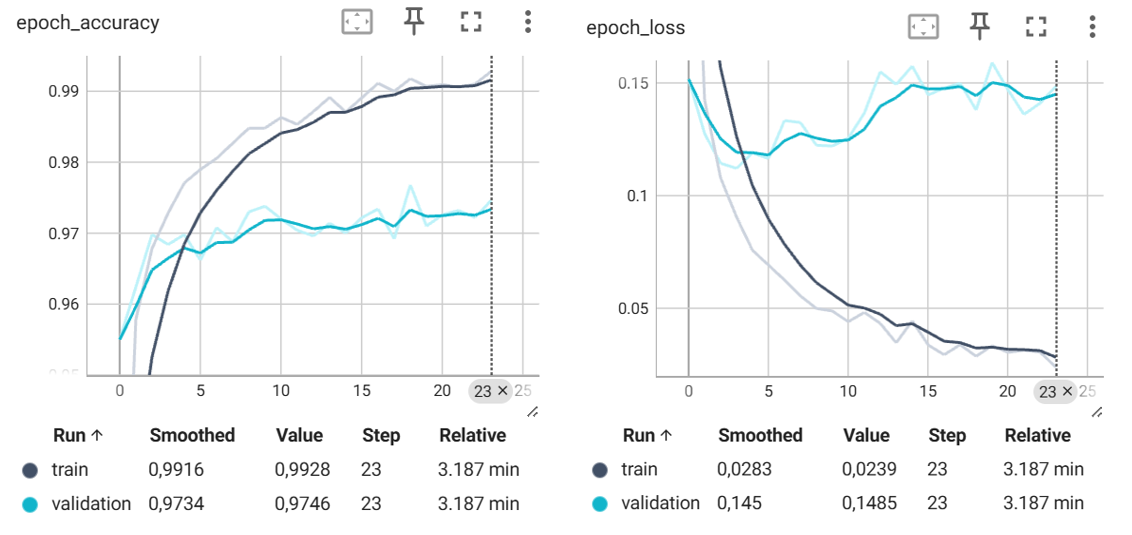

El tiempo total de entrenamiento fue de 3.187 minutos y se detuvo en el paso 23, lo que significa que el modelo completó 24 épocas (de la 0 a la 23) como ya se había visto en la salida anterior. Observamos principalmente la evolución de los resultados en los gráficos de epoch_accuracy y epoch_loss:

*   *epoch_accuracy* :  el valor de accuracy en el conjunto de entrenamiento aumenta rápidamente durante las primeras épocas, alcanzando temprano un valor cercano a 0.98. Por otro lado, la curva del conjunto de validación crece durante las primeras épocas pero se estabiliza a partir de la época 10-12, sin mejoras tan notables. Finalmente, el modelo logra clasificar correctamente un 99.28% de las imágenes del conjunto de entrenamiento y un 97.46% en validación. La diferencia entre ambos conjuntos no es muy grande, por lo que no hay un sobreajuste significativo y estos valores indican un rendimiento muy alto.


*  *epoch_loss* :  durante las primeras épocas la pérdida se reduce en ambos conjuntos, pero a partir del paso 4 la pérdida de validación deja de bajar, mientras la de entrenamiento sigue disminuyendo. Finalmente, se consigue una pérdida de 0.0239 en entrenamiento y de 0.1485 en validación. Estos valores son muy bajos, lo que confirma que el modelo aprendió de forma eficaz.


El estancamiento en las métricas del conjunto de validación a partir de cierta época podría deberse al valor del parámetro patience=20 en *EarlyStopping*, que permite continuar el entrenamiento durante 20 épocas sin mejoras. A pesar de ello, como los resultados finales son buenos, mantendremos esta configuración para los siguientes modelos para realizar comparaciones justas.

Por último, evaluamos el rendimiento final del modelo en el conjunto de prueba:

In [50]:
modelo_3capas_A = tf.keras.models.load_model("modelo_3capas_A.keras")
modelo_3capas_A.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9634 - loss: 0.1324


[0.10996848344802856, 0.9693999886512756]

El modelo logra clasificar correctamente un 96.94% de las imágenes del conjunto de prueba y obtiene una pérdida muy baja, 0.1099.
Estos resultados muestran que la red tiene un alto rendimiento y generaliza correctamente a datos que no ha visto durante el entrenamiento.

**Modelo con 3 capas ocultas (B)**

A continuación, creamos un segundo modelo con tres capas ocultas con 128, 128 y 64 neuronas, respectivamente. Al aumentar el número de neuronas, la capacidad para detectar patrones debería aumentar. Sin embargo, esto también incrementa el riesgo de sobreajuste, por lo que compararemos los resultados que se obtengan con el anterior modelo.

Para que los resultados sean comparables, mantenemos los mismos parámetros y funciones empleados para el modelo anterior (función de activación, función de pérdida, optimizador, tasa de aprendizaje y callbacks).

In [53]:
tf.keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

In [54]:
modelo_3capas_B = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

In [55]:
modelo_3capas_B.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 125,898 (491.79 KB)

 Trainable params: 125,898 (491.79 KB)

 Non-trainable params: 0 (0.00 B)

En el modelo con menos neuronas por capa teníamos 56.810 parámetros, mientras que en este contamos con 125.898 parámetros en total, ya que al incrementar el número de neuronas se introducen nuevas conexiones y pesos que aprender.

In [56]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.3)
modelo_3capas_B.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
              metrics=["accuracy"])

In [57]:
run_index = 2  # incrementa en cada nuevo entrenamiento
run_logdir = Path("my_mnist_logs") / "run_{:03d}".format(run_index)

Para evitar salidas extensas, a partir de ahora estableceremos el parámetro verbose = 0.

In [58]:
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=20)
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint("modelo_3capas_B.keras", save_best_only=True)
tensorboard_cb = tf.keras.callbacks.TensorBoard(run_logdir)
history = modelo_3capas_B.fit(X_train, y_train, epochs=100,
                    validation_data=(X_valid, y_valid),
                    callbacks=[checkpoint_cb, early_stopping_cb, tensorboard_cb],
                    verbose=0)

Veamos sus gráficos de evolución:

In [59]:
%tensorboard --logdir=./my_mnist_logs/run_002

<IPython.core.display.Javascript object>

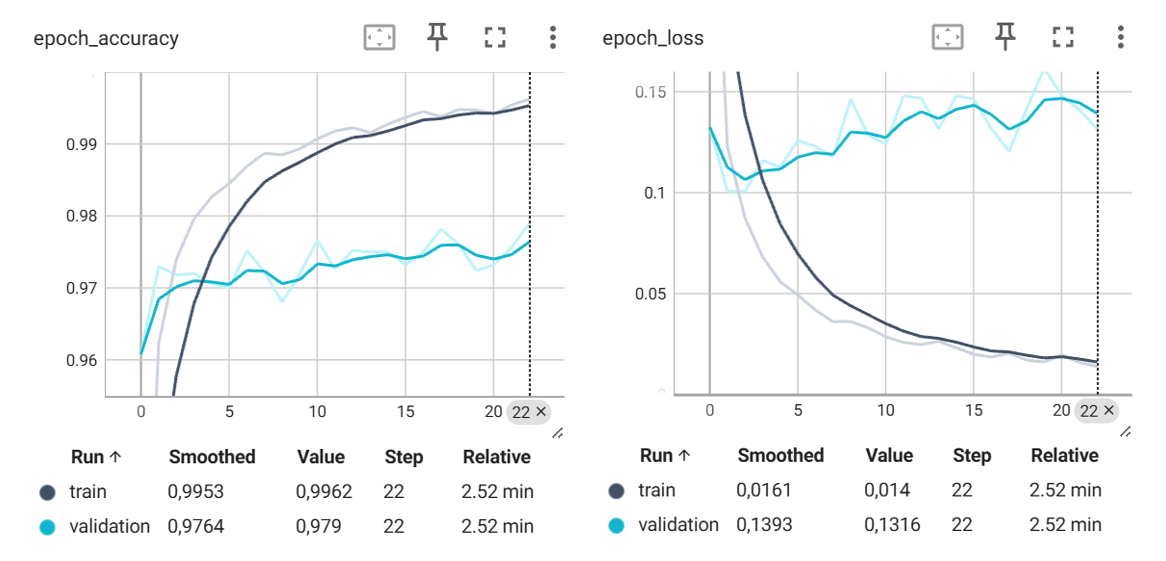

El tiempo total de entrenamiento fue de 2.52 minutos y se detuvo en el paso 22 (época 23).

*   *epoch_accuracy* :  se observa que el accuracy en la curva de entrenamiento aumenta rápidamente durante las primeras épocas, mostrando una convergencia rápida. La curva de validación también mejora progresivamente pero de forma más suave. Al final del entrenamiento, la exactitud de entrenamiento es muy alta (99.62%) y la de validación también (97.9%), indicando que el modelo tiene buen ajuste.


*  *epoch_loss* : durante las primeras épocas, la pérdida tanto en entrenamiento como en validación disminuye de manera notable. Alrededor del paso 3 se alcanza la pérdida mínima en validación, y de ahí en adelante comienza a aumentar ligeramente. Finalmente, se obtiene una pérdida de 0.014 en entrenamiento y de 0.1316 en validación, por lo que los resultados son bastante buenos a pesar de haber aumentado ligeramente la pérdida en validación.


Al igual que con el modelo anterior, se observa que podría considerarse detener el entrenamiento con *EarlyStopping* mucho antes, ya que los resultados en validación se mantienen constantes a partir de cierta época y no mejoran mucho e incluso empeoran en el caso de la pérdida.


Evaluamos el rendimiento final del modelo en el conjunto de prueba:

In [60]:
modelo_3capas_B = tf.keras.models.load_model("modelo_3capas_B.keras")
modelo_3capas_B.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9652 - loss: 0.1160


[0.10353348404169083, 0.970300018787384]

Se alcanza una exactitud del 97.03% y una pérdida de 0.104 aproximadamente en el conjunto de prueba, lo que demuestra un alto rendimiento al aplicarse en datos no vistos.


**Comparación entre modelo A y B con 3 capas ocultas**

Tras entrenar y evaluar el modelo A, con 3 capas ocultas de 64, 64 y 32 neuronas, y el modelo B, con 3 capas ocultas de 128, 128 y 64 neuronas, obtenemos los siguientes resultados:


In [110]:
%tensorboard --logdir ./my_mnist_logs

<IPython.core.display.Javascript object>

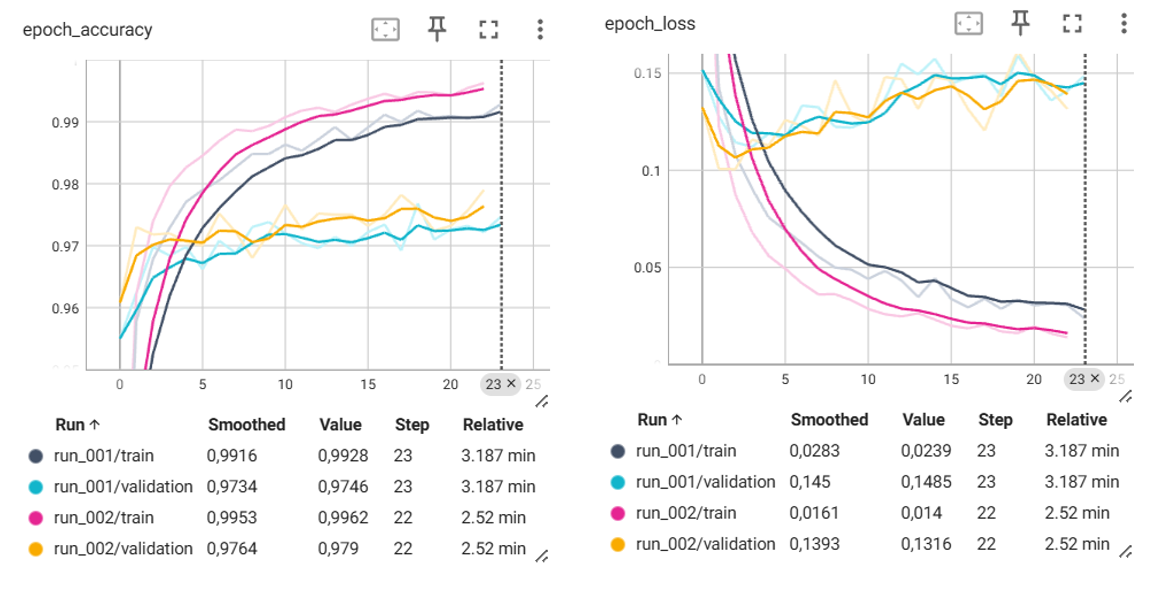

In [62]:
columnas = [
    "Capas ocultas",
    "Neuronas por capa",
    "Parámetros",
    "Época parada",
    "Tiempo entrenamiento",
    "Accuracy train",
    "Accuracy val",
    "Accuracy test",
    "Loss train",
    "Loss val",
    "Loss test"
]

datos = [
    [3, "64-64-32", 56810, 24, "3.187 min", 0.9928, 0.9746, 0.9694, 0.0239, 0.1485, 0.1099],
    [3, "128-128-64", 125898, 23, "2.52 min", 0.9962, 0.979, 0.9703, 0.014, 0.1316, 0.104]
]

modelos = ["Modelo A", "Modelo B"]
tabla = pd.DataFrame(datos, columns=columnas, index=modelos)
tabla_transpuesta = tabla.T
print(tabulate(tabla_transpuesta, headers="keys", tablefmt="fancy_grid", stralign="center", numalign="center"))

╒══════════════════════╤════════════╤════════════╕
│                      │  Modelo A  │  Modelo B  │
╞══════════════════════╪════════════╪════════════╡
│    Capas ocultas     │     3      │     3      │
├──────────────────────┼────────────┼────────────┤
│  Neuronas por capa   │  64-64-32  │ 128-128-64 │
├──────────────────────┼────────────┼────────────┤
│      Parámetros      │   56810    │   125898   │
├──────────────────────┼────────────┼────────────┤
│     Época parada     │     24     │     23     │
├──────────────────────┼────────────┼────────────┤
│ Tiempo entrenamiento │ 3.187 min  │  2.52 min  │
├──────────────────────┼────────────┼────────────┤
│    Accuracy train    │   0.9928   │   0.9962   │
├──────────────────────┼────────────┼────────────┤
│     Accuracy val     │   0.9746   │   0.979    │
├──────────────────────┼────────────┼────────────┤
│    Accuracy test     │   0.9694   │   0.9703   │
├──────────────────────┼────────────┼────────────┤
│      Loss train      │   0.02

El Modelo B consiguió obtener mejores valores en accuracy y loss en todos los conjuntos gracias a su mayor complejidad, utilizando el doble de neuronas por capa (128-128-64), lo que incrementó el número de parámetros.

Además, llama la atención que el tiempo de entrenamiento del Modelo B haya sido ligeramente inferior al Modelo A y se haya detenido una época antes a pesar de ser más complejo.

Por lo tanto, el Modelo B tiene un mejor desempeño y generalización que el Modelo A.

**3.2. MLP CON 4 CAPAS OCULTAS**

Realizamos el mismo procedimiento pero considerando una capa oculta más.

Vamos a diseñar dos modelos con cuatro capas ocultas, el primero tendrá 64, 64, 32 y 16 neuronas, mientras que el segundo contará con 128, 128, 64 y 32 neuronas.

Mantendremos los mismos parámetros para la función de activación, la función de pérdida, el optimizador, la tasa de aprendizaje y los callbacks.

Por último, al igual que con los anteriores modelos, evaluaremos cuál muestra un mejor desempeño.

**Modelo con 4 capas ocultas (A)**

In [65]:
tf.keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

In [66]:
modelo_4capas_A = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

In [67]:
modelo_4capas_A.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,178 (223.35 KB)

 Trainable params: 57,178 (223.35 KB)

 Non-trainable params: 0 (0.00 B)

Al aumentar la profundidad del modelo aumenta el número de parámetros con respecto al primer modelo de 3 capas ocultas, en el que se tenían 56.810 parámetros frente a los 57.178 que tenemos al añadir una capa oculta, ya que en total tenemos más neuronas.

In [68]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.3)
modelo_4capas_A.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
              metrics=["accuracy"])

In [69]:
run_index = 3  # incrementa en cada nuevo entrenamiento
run_logdir = Path("my_mnist_logs") / "run_{:03d}".format(run_index)


In [70]:
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=20)
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint("modelo_4capas_A.keras", save_best_only=True)
tensorboard_cb = tf.keras.callbacks.TensorBoard(run_logdir)
history = modelo_4capas_A.fit(X_train, y_train, epochs=100,
                    validation_data=(X_valid, y_valid),
                    callbacks=[checkpoint_cb, early_stopping_cb, tensorboard_cb],
                    verbose = 0)

Veamos los gráficos de evolución:

In [71]:
%tensorboard --logdir=./my_mnist_logs/run_003

<IPython.core.display.Javascript object>

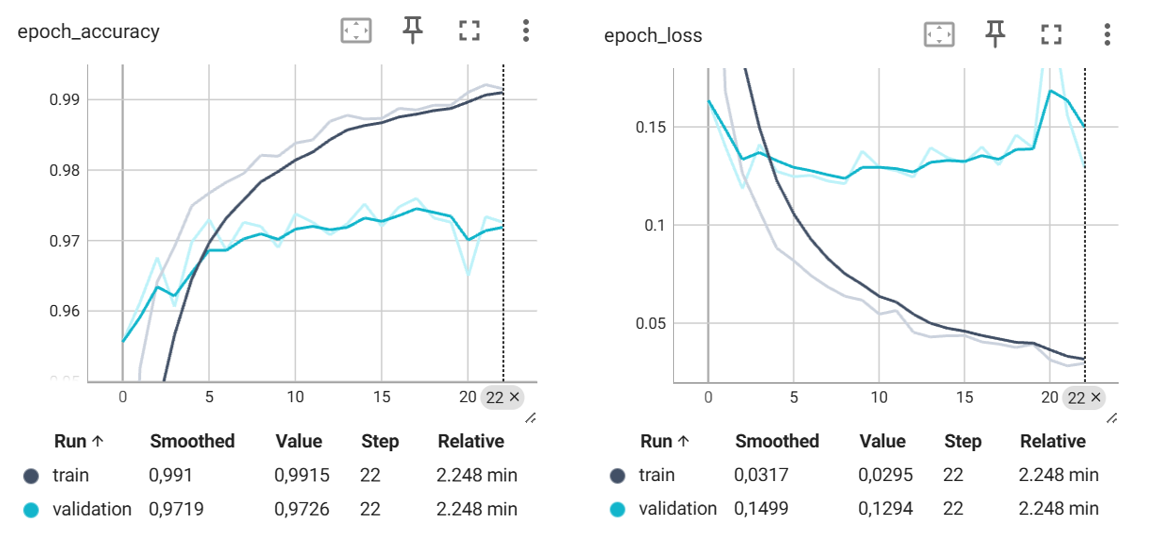

El tiempo total de entrenamiento fue de 2.248 minutos y se detuvo en el paso 22 (época 23).

*   *epoch_accuracy* :  el accuracy aumenta en ambos conjuntos durante las primeras épocas, pero alrededor de la época 10 la línea de validación se estanca mientras que la de entrenamiento sigue creciendo de forma rápida. Finalmente, se obtiene una exactitud del 99.15% en entrenamiento y 97.26% en validación.

*  *epoch_loss* : durante las primeras épocas la pérdida en entrenamiento y en validación se reduce notablemente, pero a partir de la época 9 la de validación comienza a subir ligeramente mientras que la de entrenamiento sigue disminuyendo. Al final del entrenamiento se consigue una pérdida de 0.029 en entrenamiento y 0.129 en validación.

Se obtienen conclusiones similares a las que observamos en los modelos con 3 capas ocultas en cuanto al estancamiento en los resultados de validación.

Por último, evaluamos el modelo en el conjunto de prueba:

In [72]:
modelo_4capas_A = tf.keras.models.load_model("modelo_4capas_A.keras")
modelo_4capas_A.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9603 - loss: 0.1517


[0.13079750537872314, 0.965399980545044]

Se obtiene una exactitud en las predicciones del 96.54% en el conjunto de prueba, y una pérdida de 0.1308, por lo que el modelo parece tener un buen rendimiento con datos no vistos.

**Modelo con 4 capas ocultas (B)**

A continuación, creamos un segundo modelo con cuatro capas ocultas con 128, 128, 64 y 32 neuronas, respectivamente. Al igual que con los modelos anteriores, vamos a ver cómo influye el aumento del número de neuronas en el aprendizaje.

Para que los resultados sean comparables, empleamos los mismos parámetros y funciones que en el anterior modelo.

In [75]:
tf.keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

In [76]:
modelo_4capas_B = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

In [77]:
modelo_4capas_B.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 127,658 (498.66 KB)

 Trainable params: 127,658 (498.66 KB)

 Non-trainable params: 0 (0.00 B)

Al aumentar tanto la profundidad de la red como el número de neuronas obtenemos una red aún más compleja. En el anterior modelo con cuatro capas ocultas pero menor número de neuronas por capa teníamos 57.178 parámetros, mientras que al aumentar el número de neuronas contamos con 127.658 parámetros.

In [78]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.3)
modelo_4capas_B.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
              metrics=["accuracy"])

In [79]:
run_index = 4  # incrementa en cada nuevo entrenamiento
run_logdir = Path("my_mnist_logs") / "run_{:03d}".format(run_index)


In [80]:
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=20)
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint("modelo_4capas_B.keras", save_best_only=True)
tensorboard_cb = tf.keras.callbacks.TensorBoard(run_logdir)
history = modelo_4capas_B.fit(X_train, y_train, epochs=100,
                    validation_data=(X_valid, y_valid),
                    callbacks=[checkpoint_cb, early_stopping_cb, tensorboard_cb],
                    verbose=0)

In [81]:
%tensorboard --logdir=./my_mnist_logs/run_004

<IPython.core.display.Javascript object>

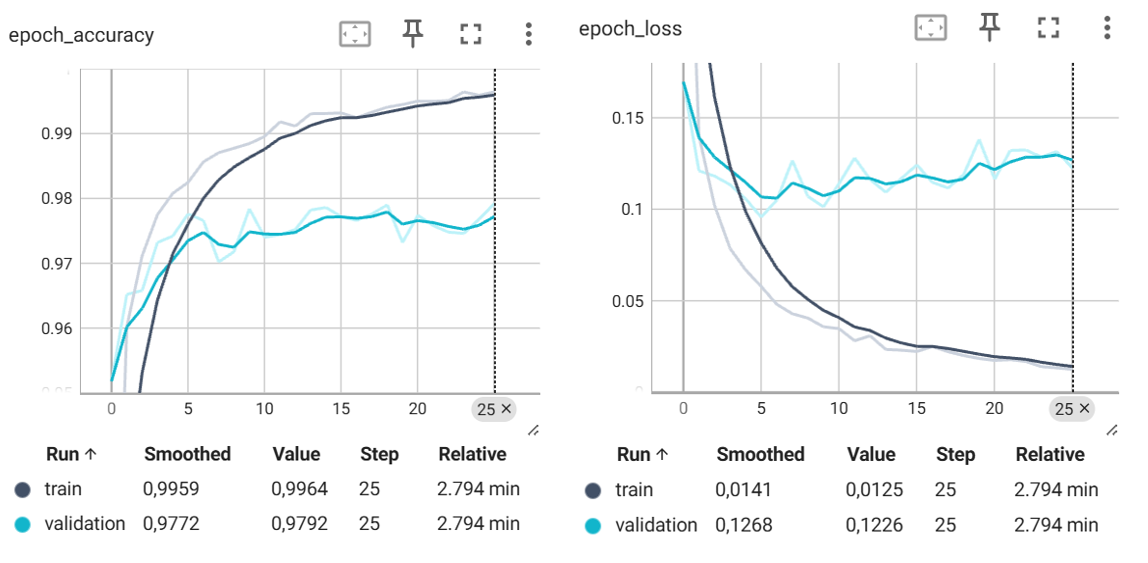

El tiempo total de entrenamiento fue de 2.794 minutos y se detuvo en el paso 25 (época 26).

*   *epoch_accuracy* :  el accuracy comienza siendo muy alto en las primeras épocas tanto en entrenamiento como en validación (entre 0.97 y 0.98). Se observa que aumenta en ambos conjuntos durante todo el entrenamiento, pero de forma más suave al final en el conjunto de validación. Finalmente, se conseguir predecir correctamente un 99.64% de las imágenes del conjunto de entrenamiento y un 97.92% del conjunto de validación.

*  *epoch_loss* : durante las primeras épocas la pérdida en entrenamiento y en validación se reduce notablemente, pero se observa un aumento del paso 6 en adelante en el conjunto de validación. Al final del entrenamiento se consigue una pérdida de 0.013 en entrenamiento y 0.123 en validación.

De nuevo, estos resultados sugieren que podríamos parar el entrenamiento antes. Sin embargo, los resultados finales son bastante buenos a pesar de ello.

In [82]:
modelo_4capas_B = tf.keras.models.load_model("modelo_4capas_B.keras")
modelo_4capas_B.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9730 - loss: 0.1063


[0.08839825540781021, 0.9768000245094299]

Por último, se obtiene una exactitud del 97.68% en las predicciones con el conjunto de prueba y una pérdida de 0.088, lo cual sugiere que el modelo tiene muy buena capacidad de generalización.

**Comparación entre modelo A y B con 4 capas ocultas**

Tras entrenar y evaluar el modelo A, con 4 capas ocultas de 64, 64, 32 y 16 neuronas, y el modelo B, con 4 capas ocultas de 128, 128, 64 y 32 neuronas, obtenemos los siguientes resultados:

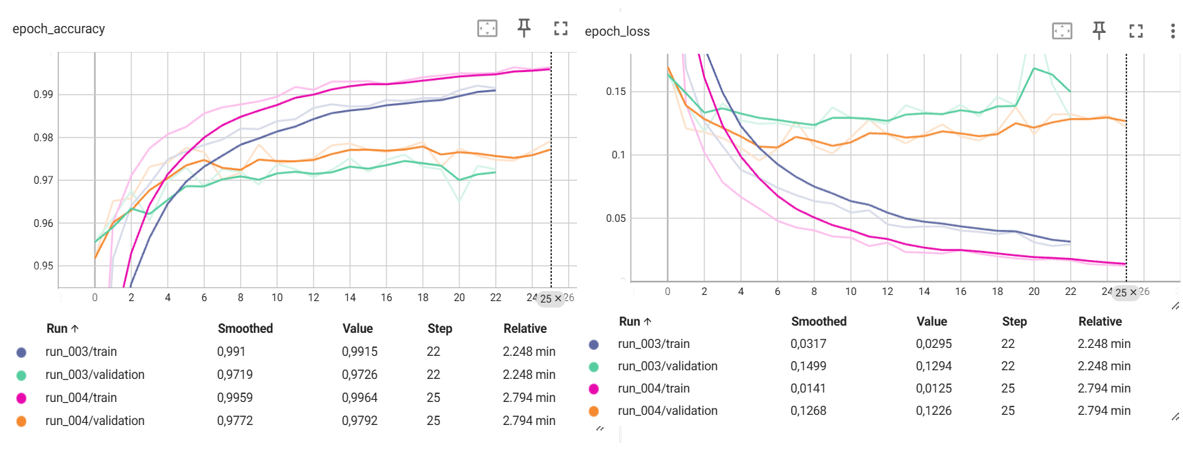

In [85]:
columnas = [
    "Capas ocultas",
    "Neuronas por capa",
    "Parámetros",
    "Época parada",
    "Tiempo entrenamiento",
    "Accuracy train",
    "Accuracy val",
    "Accuracy test",
    "Loss train",
    "Loss val",
    "Loss test"
]

datos = [
    [4, "64-64-32-16", 57178, 23, "2.248 min", 0.9915, 0.9726, 0.9654, 0.029, 0.129, 0.131],
    [4, "128-128-64-32", 127658, 26, "2.794 min", 0.9964, 0.9792, 0.9768, 0.013, 0.123, 0.088]
]

modelos = ["Modelo A", "Modelo B"]
tabla = pd.DataFrame(datos, columns=columnas, index=modelos)
tabla_transpuesta = tabla.T
print(tabulate(tabla_transpuesta, headers="keys", tablefmt="fancy_grid", stralign="center", numalign="center"))

╒══════════════════════╤═════════════╤═══════════════╕
│                      │  Modelo A   │   Modelo B    │
╞══════════════════════╪═════════════╪═══════════════╡
│    Capas ocultas     │      4      │       4       │
├──────────────────────┼─────────────┼───────────────┤
│  Neuronas por capa   │ 64-64-32-16 │ 128-128-64-32 │
├──────────────────────┼─────────────┼───────────────┤
│      Parámetros      │    57178    │    127658     │
├──────────────────────┼─────────────┼───────────────┤
│     Época parada     │     23      │      26       │
├──────────────────────┼─────────────┼───────────────┤
│ Tiempo entrenamiento │  2.248 min  │   2.794 min   │
├──────────────────────┼─────────────┼───────────────┤
│    Accuracy train    │   0.9915    │    0.9964     │
├──────────────────────┼─────────────┼───────────────┤
│     Accuracy val     │   0.9726    │    0.9792     │
├──────────────────────┼─────────────┼───────────────┤
│    Accuracy test     │   0.9654    │    0.9768     │
├─────────

Con el Modelo B se obtienen mejores valores en accuracy y loss en todos los conjuntos (especialmente en test) gracias a su mayor complejidad. Este modelo tardó 3 épocas más y unos segundos más en el entrenamiento que el Modelo A, pero no es una diferencia muy grande.

En resumen, el Modelo B tiene un mejor desempeño y generalización que el Modelo A, ya que al considerar más neuronas en las capas logra aprender mejor las características de las imágenes sin sobreajustarse demasiado y su tiempo de entrenamiento no es mucho mayor.

Por lo tanto, tanto con 3 capas como con 4 capas nos quedamos con los modelos que tienen un mayor número de neuronas en cada capa, ya que consigue aprender más información sobre las imágenes y predecir mejor.

**4. AJUSTE DE LA TASA DE APRENDIZAJE EN LOS MEJORES MODELOS**

En la sección anterior se entrenaron dos modelos con 3 capas ocultas y dos con 4 capas ocultas utilizando el learning rate obtenido mediante el callback *ExponentialLearningRate*, que era 0.3. Tras comparar sus resultados, los modelos que mostraron el mejor rendimiento fueron el de 3 capas ocultas con 128, 128 y 64 neuronas, y el de 4 capas ocultas con 128, 128, 64 y 32 neuronas.

En esta sección, se reentrenan exclusivamente estos dos modelos utilizando un LR más bajo. El objetivo es evaluar si una tasa de aprendizaje más pequeña permite una convergencia más estable y un rendimiento superior al observado anteriormente.

**4.1. MLP CON 3 CAPAS OCULTAS**

In [88]:
tf.keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

In [89]:
modelo_3capas_B2 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

En lugar de un LR de 0.3, vamos a considerar un valor de 0.1, ya que hemos observado que en términos generales los modelos convergían rápidamente.

In [90]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.1)
modelo_3capas_B2.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
              metrics=["accuracy"])

In [91]:
run_index = 5  # incrementa en cada nuevo entrenamiento
run_logdir = Path("my_mnist_logs") / "run_{:03d}".format(run_index)

In [92]:
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=20)
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint("modelo_3capas_B2.keras", save_best_only=True)
tensorboard_cb = tf.keras.callbacks.TensorBoard(run_logdir)
history = modelo_3capas_B2.fit(X_train, y_train, epochs=100,
                    validation_data=(X_valid, y_valid),
                    callbacks=[checkpoint_cb, early_stopping_cb, tensorboard_cb],
                    verbose=0)

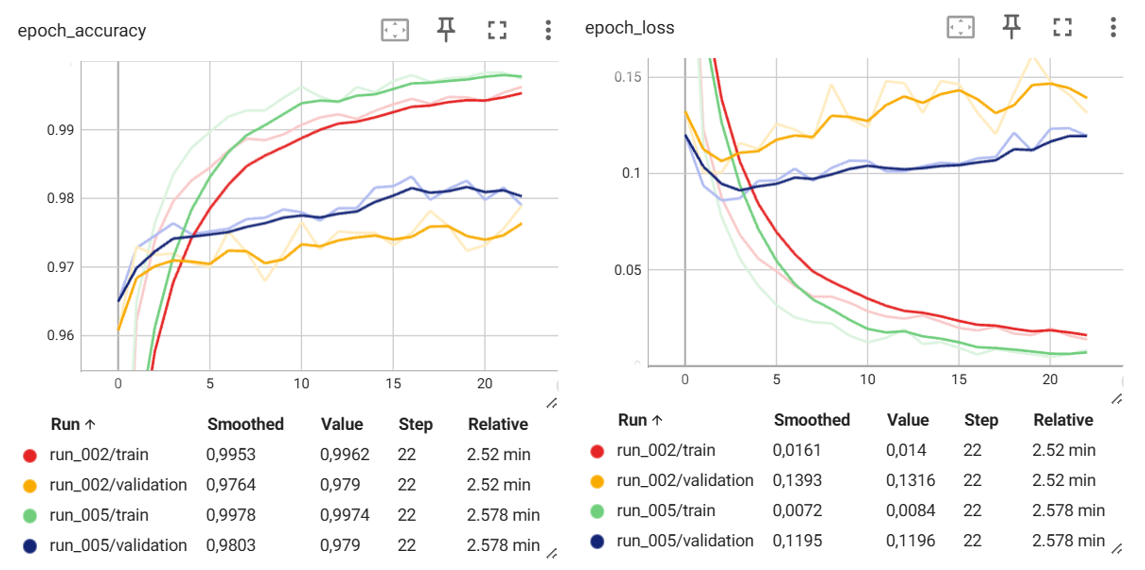

La forma de las curvas con LR=0.3 (run_002) y LR=0.1 (run_005) se asemejan bastante. En cambio, con un LR de 0.1 el accuracy es más alto desde el principio tanto en entrenamiento como en validación. La pérdida también es más baja durante todo el entrenamiento en ambos conjuntos considerando un LR más bajo. Finalmente, se alcanzan valores similares, ligeramente mejores con un LR de 0.1.


Aunque entrenar con LR más pequeño ha requerido un poco más tiempo de entrenamiento, el resultado final es una mejor generalización, menor loss y mayor accuracy.

In [94]:
modelo_3capas_B2 = tf.keras.models.load_model("modelo_3capas_B2.keras")
modelo_3capas_B2.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9700 - loss: 0.0983


[0.08148600161075592, 0.9753000140190125]

En el conjunto de prueba con una tasa de aprendizaje de 0.1 se
obtiene un accuracy del 97.53% y una pérdida de 0.081, resultados ligeramente mejores que los que se obtuvieron considerando un LR de 0.3.


**4.2. MLP CON 4 CAPAS OCULTAS**

Observamos cómo cambian los resultados en el modelo con 4 capas ocultas considerando un LR de 0.1:

In [97]:
tf.keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

In [98]:
modelo_4capas_B2 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

In [99]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.1)
modelo_4capas_B2.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
              metrics=["accuracy"])

In [100]:
run_index = 6  # incrementa en cada nuevo entrenamiento
run_logdir = Path("my_mnist_logs") / "run_{:03d}".format(run_index)

In [101]:
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=20)
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint("modelo_4capas_B2.keras", save_best_only=True)
tensorboard_cb = tf.keras.callbacks.TensorBoard(run_logdir)
history = modelo_4capas_B2.fit(X_train, y_train, epochs=100,
                    validation_data=(X_valid, y_valid),
                    callbacks=[checkpoint_cb, early_stopping_cb, tensorboard_cb],
                    verbose=0)

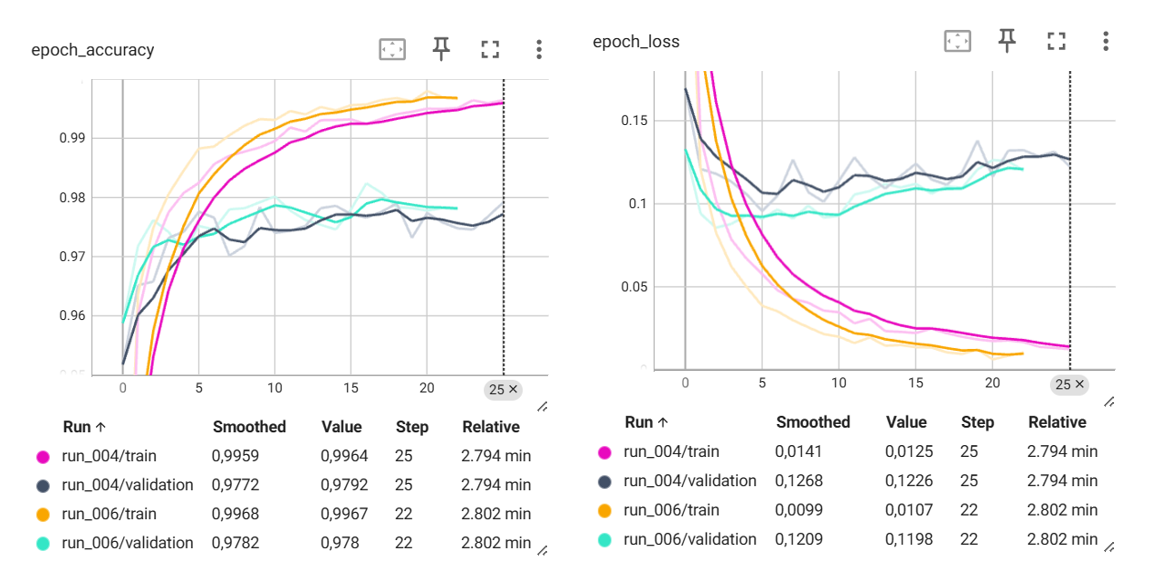

Se observa que run_006 (LR=0.1) alcanza de forma más rápida un accuracy alto durante las primeras épocas, superando ligeramente a run_004 (LR=0.3) en la fase inicial del entrenamiento. Sin embargo, ambos modelos alcanzan finalmente valores muy similares. En cuanto a la validación, run_004 termina con un valor ligeramente superior, indicando una mejor generalización con LR=0.3 que con LR=0.1.

Por otro lado, el gráfico de loss, el modelo con LR=0.1 (run_006) desciende más rápido y alcanza pérdidas más bajas tanto en entrenamiento como en validación. Aunque con LR=0.3 (run_004) también reduce su pérdida de manera eficiente, termina con una pérdida ligeramente mayor en validación.

En conjunto, con una tasa de aprendizaje de 0.1 obtenemos un proceso más estable.

In [103]:
modelo_4capas_B2 = tf.keras.models.load_model("modelo_4capas_B2.keras")
modelo_4capas_B2.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9703 - loss: 0.1001


[0.08467445522546768, 0.9728999733924866]

En el conjunto de prueba los resultados son muy similares a los obtenidos con un LR de 0.3.

En resumen, el LR de 0.3 acelera la convergencia pero introduce más inestabilidad en validación, mientras que el LR de 0.1 consigue mayor estabilidad y resultados similares o mejores.

**4.3. COMPARACIÓN FINAL**

Finalmente vamos a comparar los resultados finales tanto con 3 como con 4 capas ocultas considerando un LR de 0.3 y de 0.1:

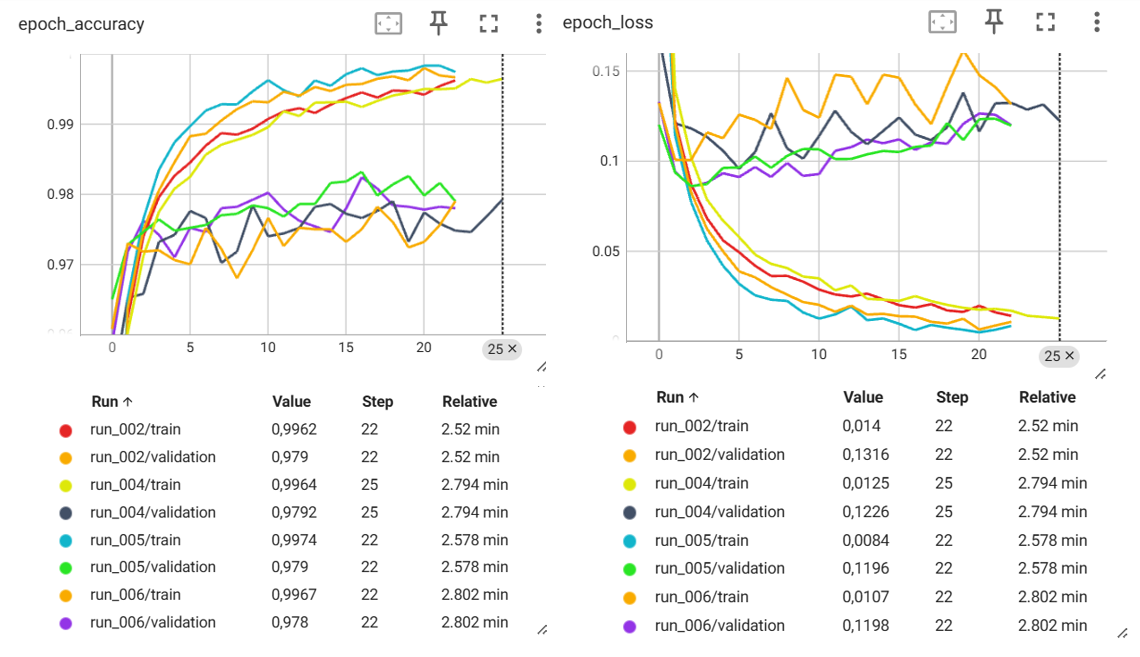

In [105]:
columnas = [
    "Capas ocultas",
    "Neuronas por capa",
    "Learning Rate",
    "Época parada",
    "Tiempo entrenamiento",
    "Accuracy train",
    "Accuracy val",
    "Accuracy test",
    "Loss train",
    "Loss val",
    "Loss test"
]

datos = [
    [3, "128-128-64", 0.3, 23, "2.52 min", 0.9962, 0.979, 0.9703, 0.014, 0.1316, 0.104],
    [3, "128-128-64", 0.1, 23, "2.578 min", 0.9974, 0.979, 0.975, 0.008, 0.119, 0.081],
    [4, "128-128-64-32", 0.3, 26, "2.794 min", 0.9964, 0.979, 0.9768, 0.013, 0.123, 0.088],
    [4, "128-128-64-32", 0.1, 23, "2.802 min", 0.9967, 0.978, 0.9729, 0.0107, 0.1198, 0.085]
]

modelos = ["Modelo A", "Modelo A2", "Modelo B", "Modelo B2"]
tabla = pd.DataFrame(datos, columns=columnas, index=modelos)
tabla_transpuesta = tabla.T
print(tabulate(tabla_transpuesta, headers="keys", tablefmt="fancy_grid", stralign="center", numalign="center"))

╒══════════════════════╤════════════╤═════════════╤═══════════════╤═══════════════╕
│                      │  Modelo A  │  Modelo A2  │   Modelo B    │   Modelo B2   │
╞══════════════════════╪════════════╪═════════════╪═══════════════╪═══════════════╡
│    Capas ocultas     │     3      │      3      │       4       │       4       │
├──────────────────────┼────────────┼─────────────┼───────────────┼───────────────┤
│  Neuronas por capa   │ 128-128-64 │ 128-128-64  │ 128-128-64-32 │ 128-128-64-32 │
├──────────────────────┼────────────┼─────────────┼───────────────┼───────────────┤
│    Learning Rate     │    0.3     │     0.1     │      0.3      │      0.1      │
├──────────────────────┼────────────┼─────────────┼───────────────┼───────────────┤
│     Época parada     │     23     │     23      │      26       │      23       │
├──────────────────────┼────────────┼─────────────┼───────────────┼───────────────┤
│ Tiempo entrenamiento │  2.52 min  │  2.578 min  │   2.794 min   │   2.802 

Se observa que el modelo con el que se obtiene una mayor exactitud es con el Modelo B (97.68%) , es decir, considerando 4 capas ocultas con 128-128-64-32 neuronas y un LR de 0.3. En cambio, el que obtiene mejor valor de pérdida en test es el Modelo A2 (0.081), es decir, el que considera 3 capas con 128-128-64 neuronas y un LR de 0.1. A pesar de ello, se asemeja bastante al valor de pérdida obtenido en el Modelo B y B2.

Para analizar también el comportamiento de los modelos clasificando cada categoría, calculamos las matrices de confusión para cada uno de los modelos evaluados en el conjunto de prueba:

In [106]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_confusion_matrix_subplot(model, X_test, y_test, title, ax):
    y_pred = model.predict(X_test)
    y_pred_classes = np.argmax(y_pred, axis=1)

    if len(y_test.shape) > 1:
        y_true = np.argmax(y_test, axis=1)
    else:
        y_true = y_test

    cm = confusion_matrix(y_true, y_pred_classes)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
    ax.set_title(title)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


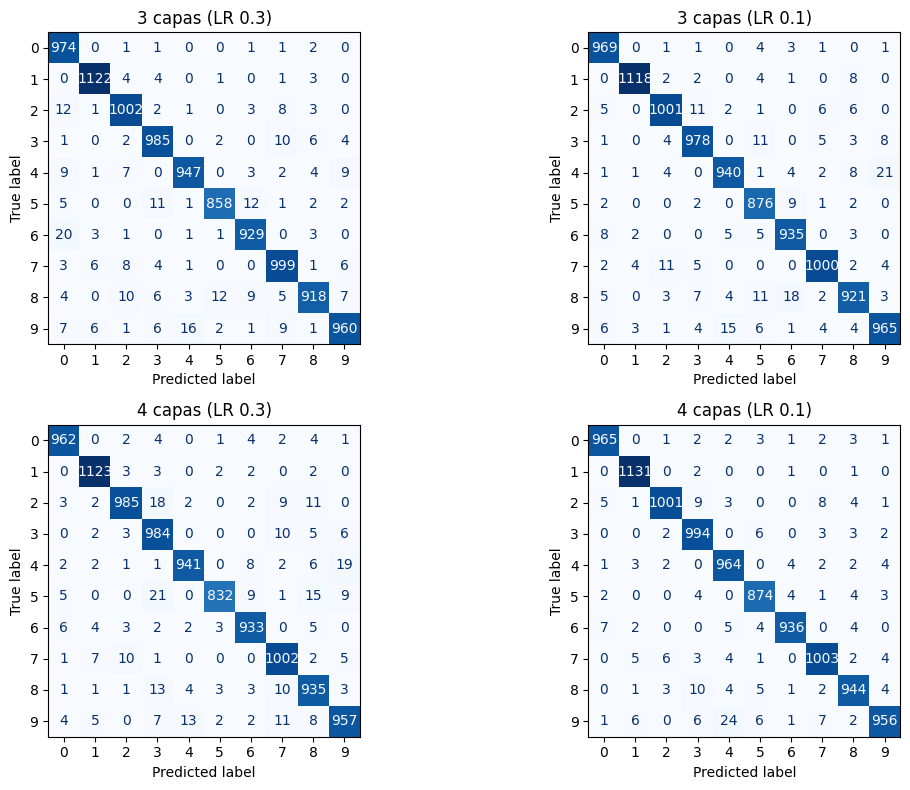

In [107]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

plot_confusion_matrix_subplot(
    modelo_3capas_A, X_test, y_test,
    "3 capas (LR 0.3)", axs[0, 0]
)

plot_confusion_matrix_subplot(
    modelo_3capas_B, X_test, y_test,
    "3 capas (LR 0.1)", axs[0, 1]
)

plot_confusion_matrix_subplot(
    modelo_4capas_A, X_test, y_test,
    "4 capas (LR 0.3)", axs[1, 0]
)

plot_confusion_matrix_subplot(
    modelo_4capas_B, X_test, y_test,
    "4 capas (LR 0.1)", axs[1, 1]
)

plt.tight_layout()
plt.show()


La diagonal principal de las matrices representa los aciertos en la clasificación de las imágenes. En todos los modelos se observa un mejor desempeño en la clasificación de los dígitos 1 y 7, probablemente debido a su mayor aparición en el conjunto de datos. El dígito 5, al ser la clase con menos ejemplos, presenta un rendimiento ligeramente inferior.

Se aprecia que el aumento de 3 a 4 capas produce una mejora en el rendimiento y que con una tasa de aprendizaje de 0.1 se obtienen menos errores en las clasificaciones tanto en el modelo de 3 capas como en el de 4 capas.

En conjunto, el modelo más preciso es el de 4 capas ocultas con 128-128-64-32 neuronas y con una tasa de aprendizaje de 0.1.

**5. CONCLUSIONES**

Tras evaluar cómo el número de neuronas, el número de capas ocultas y la tasa de aprendizaje afectan el desempeño en la clasificación de dígitos en el conjunto de datos MNIST, se obtienen las siguientes conclusiones:

Antes del entrenamiento, se realizó una búsqueda del learning rate adecuado graficando la tasa de aprendizaje frente a la pérdida, obteniendo que un valor de 0.3 era el más conveniente.

Inicialmente, se compararon dos modelos de tres capas, uno con 64-64-32 neuronas y otro con 128-128-64 neuronas. Ambos modelos fueron entrenados usando la función de activación relu en las capas ocultas, softmax en la capa de salida, y optimizados mediante SGD. Los resultados mostraron que el modelo con mayor cantidad de neuronas alcanzó mejor exactitud en el conjunto de validación.

De manera similar, se compararon dos modelos de cuatro capas, con 64-64-32-16 y 128-128-64-32 neuronas respectivamente, siguiendo la misma configuración de hiperparámetros, donde nuevamente el modelo más grande obtuvo un mejor desempeño.

Posteriormente, los dos modelos ganadores de cada grupo fueron reentrenados reduciendo la tasa de aprendizaje de 0.3 a 0.1, observándose resultados similares, pero algo más estables.

Finalmente, se evaluó la clasificación sobre el conjunto de prueba mediante matrices de confusión, donde se vio que el mejor modelo fue el de cuatro capas con 128-128-64-32 neuronas y una tasa de aprendizaje de 0.1, alcanzando un accuracy cercano al 97-98%.